# Rainbow Bead Calibration

In this tutorial, we have data that was recorded with a 21 marker panel on a BD A3. As all data was recorded within a week using dyes from the same lot, we will assume fixed dye spectra. However, we will still use the concurrently measured rainbow beads to calibrate the A3, and fit marker normalization factors from the reference sample.

As a first step, we perform the rainbow bead calibration. This is independent of the marker scaling, and if only cytometer stability is required this can be applied to arbitrary flow cytometry data.

- FIX PATH STRUCTURE

In [1]:
import numpy as np
import pandas as pd
import anndata
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import PIL

#import cytovanni

import sys
local_path = os.path.expanduser("~/cytovanni_publish/Cytovanni/src")
if local_path not in sys.path:
    sys.path.insert(0, local_path)
import cytovanni
cytovanni.__version__

'1.1.0'

In [2]:
raw_data_path = os.path.expanduser("~/Cytovanni/data/example_fixed-spectra/")
data_path = os.path.expanduser("~/Cytovanni/docs/tutorials/integration_fixed-spectra/")

We strongly suggest using a GPU for speedup.

In [3]:
import torch
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(device)

cuda:0


Here, we use a small version of our A3 configuration with 21 instead of the full 23 fluorescence channels.

In [4]:
cytoconfig = cytovanni.utils.CytometerConfiguration_A3small()

## Data Overview

The reference samples were recorded on mostly consecutive days at fixed cytometer settings (note that all files have the same settings hash), together with 8 peak rainbow beads.

In [5]:
cytovanni.io.read_folder_timestamps(raw_data_path, cytoconfig)

,date,begin_record,end_record,UTC,set_hash
Sphero Rainbow Calibration Particles (8Peaks) 12_11_2021.fcs,12-NOV-2021,10:11:39,10:13:40,1.636708e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
RF_12_11_2021.fcs,12-NOV-2021,11:11:34,11:12:17,1.636712e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
Sphero Rainbow Calibration Particles (8Peaks) 15_11_2021.fcs,15-NOV-2021,03:03:51,03:04:31,1.636942e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
RF_15_11_2021.fcs,15-NOV-2021,03:04:50,03:05:19,1.636942e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
Sphero Rainbow Calibration Particles (8Peaks) 16_11_2021.fcs,16-NOV-2021,01:25:30,01:27:24,1.637022e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
RF_16_11_2021.fcs,16-NOV-2021,02:06:27,02:06:58,1.637025e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
Sphero Rainbow Calibration Particles (8Peaks) 18_11_2021.fcs,18-NOV-2021,01:21:07,01:23:13,1.637195e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
RF_18_11_2021.fcs,18-NOV-2021,02:03:25,02:03:57,1.637197e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
Sphero Rainbow Calibration Particles (8Peaks) 22_11_2021.fcs,21-NOV-2021,23:44:06,23:45:46,1.637535e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...
RF_22_11_2021.fcs,22-NOV-2021,00:27:02,00:27:28,1.637537e+09,298372167d5e3f94f4bb6799fb5c52ee7440bea08291ce...


## Cytometer Standardization

### Prepare Data

We first collect all the necessary metadata of the rainbow bead measurements.

In [6]:
meta = pd.DataFrame([sorted(list(filter(lambda x: x.startswith("Sphero"), os.listdir(raw_data_path))))], index=["filename"]).T
meta["type_rb_Npeak"] = 8 # number of peaks
meta["type_rb"] = "default" # type in case multiple different lots/rainbow beads are used
meta["batch_rb"] = meta["filename"].apply(lambda x: x[-14:-4]) # name for the batches
meta

,filename,type_rb_Npeak,type_rb,batch_rb
0,Sphero Rainbow Calibration Particles (8Peaks) ...,8,default,12_11_2021
1,Sphero Rainbow Calibration Particles (8Peaks) ...,8,default,15_11_2021
2,Sphero Rainbow Calibration Particles (8Peaks) ...,8,default,16_11_2021
3,Sphero Rainbow Calibration Particles (8Peaks) ...,8,default,18_11_2021
4,Sphero Rainbow Calibration Particles (8Peaks) ...,8,default,22_11_2021
5,Sphero Rainbow Calibration Particles (8Peaks) ...,8,default,23_11_2021


Then we process the raw data, gating on singlets and initially separating the different peaks.

In [7]:
# make the necessary paths
from pathlib import Path
Path(os.path.join(data_path, "rainbow", "data")).mkdir(parents=True, exist_ok=True)
Path(os.path.join(data_path, "rainbow", "plot_gate")).mkdir(parents=True, exist_ok=True)
Path(os.path.join(data_path, "rainbow", "plot_gmm_pre")).mkdir(parents=True, exist_ok=True)
Path(os.path.join(data_path, "rainbow", "plot_gmm_post")).mkdir(parents=True, exist_ok=True)

def load_clean_plot_save__single_measurement(row):
    # read the rainbow bead measurement
    adata = cytovanni.io.readfcs_rainbow_sample(os.path.join(raw_data_path, row["filename"]), # file path
                                                cytoconfig, # cytoconfig
                                                N_rainbow_peak=row["type_rb_Npeak"], # number of peaks
                                                name=row["batch_rb"] +"___"+ os.path.basename(row["filename"]), # name for the measurement
                                                rainbow_type=row["type_rb"], # rainbow bead lot, irrelevant here as we only used a single lot
                                                rainbow_batch=row["batch_rb"] # name of the batch for the measurement, usually not required but easier to access later with useful names
                                               )
    
    # first do a simple singlet gating of the beads, this can be skipped if the .fcs files are already manually gated on singlets
    plot_path = os.path.join(data_path, "rainbow", "plot_gate", f"scattergate_{adata.uns['name_uid']}.jpg")
    adata = cytovanni.gating.gate_scatter_bead_sample(adata, plotpath=plot_path )
    
    # then fit a simple Gaussian mixture model and plot the result
    cytovanni.rainbow.fit_rainbow_GMM(adata)
    plot_path = os.path.join(data_path, "rainbow", "plot_gmm_pre", f"gmm_pre_{adata.uns['name_uid']}.jpg")
    cytovanni.rainbow.plot_rainbow_channel_GMM_single(adata, savepath=plot_path)
    
    # Do additional GMM gating for cleaner peaks
    gate_mask = cytovanni.rainbow.get_rainbow_GMM_gate(adata, cutoff=-2, dropmaxpercent=10)
    adata = adata[gate_mask].copy()
    
    # then run the GMM fit again and again plot the result
    cytovanni.rainbow.fit_rainbow_GMM(adata)
    plot_path = os.path.join(data_path, "rainbow", "plot_gmm_post", f"gmm_post_{adata.uns['name_uid']}.jpg")
    cytovanni.rainbow.plot_rainbow_channel_GMM_single(adata, savepath=plot_path)
    
    # And save the resulting cleaned data
    cytovanni.io.write_rainbow_h5ad(adata, os.path.join(data_path, "rainbow", "data", f"data_{adata.uns['name_uid']}.h5ad"))

# iterate over all rainbow bead measurements
for name, row in tqdm(meta.iterrows(), total=meta.shape[0]):
    load_clean_plot_save__single_measurement(row)

100%|██████████| 6/6 [02:33<00:00, 25.55s/it]


This generates the cleaned data, as well as quality control plots for the gating and GMM fit.

While our gating approach usually works fine, it may occasionally fail. So it is usually a good idea to quickly skim all the QC plots to make sure everything worked, and rerun any samples where the automatic gating failed with different parameters. As a fallback, gating on singlets manually and skipping the automated gating step is also possible.

In [8]:
# While the id for each rainbow bead measurement (A3-1637625852 etc.) is unique and stable, it is dependent on the timezone of the machine, so we find the file this way
def find_matching_file(folder, name):
    files = list(filter(lambda x: name in x, os.listdir(folder)))
    return os.path.join(folder, files[0])

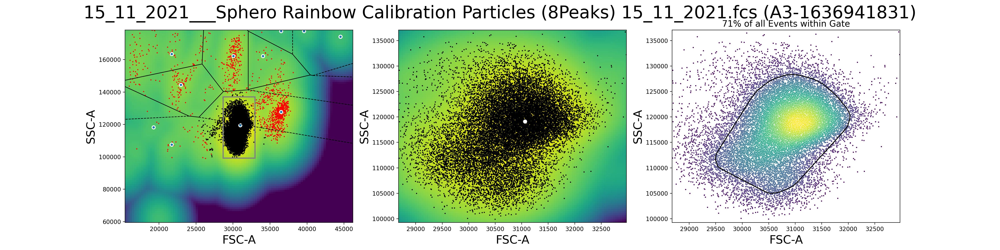

In [9]:
PIL.Image.open(find_matching_file(os.path.join(data_path, "rainbow", "plot_gate"), f"15_11_2021"))

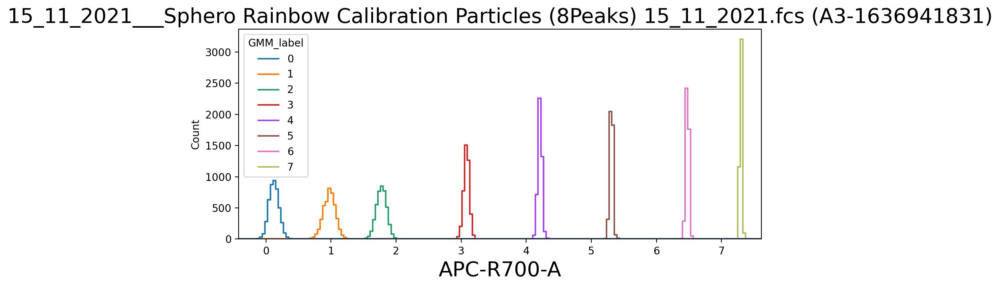

In [10]:
PIL.Image.open(find_matching_file(os.path.join(data_path, "rainbow", "plot_gmm_pre"), f"15_11_2021"))

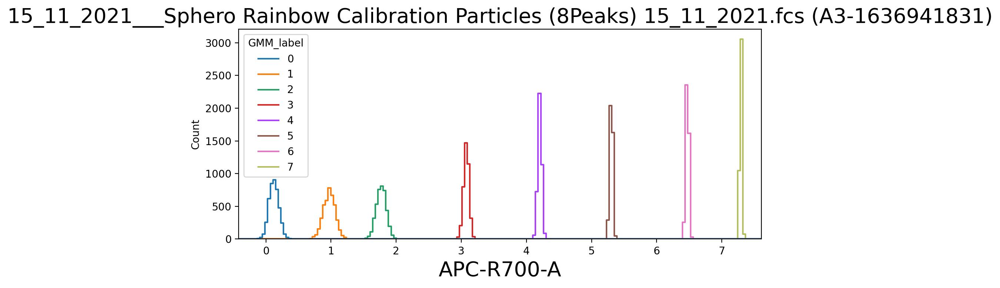

In [11]:
PIL.Image.open(find_matching_file(os.path.join(data_path, "rainbow", "plot_gmm_post"), f"15_11_2021"))

Usually, our automated gating approach should yield reasonable results. However, some cytometers will split the singlet peak into two adjacent peaks etc., so cytovanni.gating.gate_scatter_bead_sample also implements two options 'robust' and 'very robust' that should be able to deal with this. As a fallback, it is also possible to do the gating manually beforehand and skip this step.

In [12]:
?cytovanni.gating.gate_scatter_bead_sample

Signature:
cytovanni.gating.gate_scatter_bead_sample(
    adata,
    gatechannels=None,
    plot=False,
    plotpath='',
    apply=True,
    titlefct=<function <lambda> at 0x146ee23e3240>,
    robust=False,
    very_robust=False,
)
Docstring:
Gate bead sample, using the same approach as AutoSpill.

:param adata: AnnData. The sample.

:param gatechannels: list or None. The two channels to use for the scatter gating, if None defaults to output of get_default_scatter_gate_channels() from cytometer configuration.

:param plot: bool. Whether to show the corresponding summary plot.

:param plotpath: str. Path to save the summary plot to.

:param apply: bool. Whether to apply the gating directly, or only store in 'keepmask_RB_scatter'.

:param titlefct: lambda. Function to get plot title from adata, set arbitrary name by passing (lamba x: "name").

:param robust: bool. Some beads have patterns like two close peaks instead of only one etc., the robust version changes some parameters to accomod

Depending on how clean the rainbow beads already are, the additional GMM gating step can also be skipped.

### Fit Rainbow Mixture Model

Now we first read the cleaned data.

In [5]:
files = list(filter(lambda x: x.endswith(".h5ad"), os.listdir(os.path.join(data_path, "rainbow", "data"))))
rb_adatas = [cytovanni.io.read_rainbow_h5ad(os.path.join(data_path, "rainbow", "data", file)) for file in tqdm(files, mininterval=1)]
rb_adatas.sort(key=lambda ad: ad.uns["UTC"])

100%|██████████| 6/6 [00:00<00:00, 13.98it/s]


And then fit the full rainbow mixture model. All the necessary metadata was already added in the previous step.

14:44:36 - Initializing Dataset
14:44:37 - Fit Initialization


100%|██████████| 1000/1000 [00:21<00:00, 47.07it/s, nll=26.4]


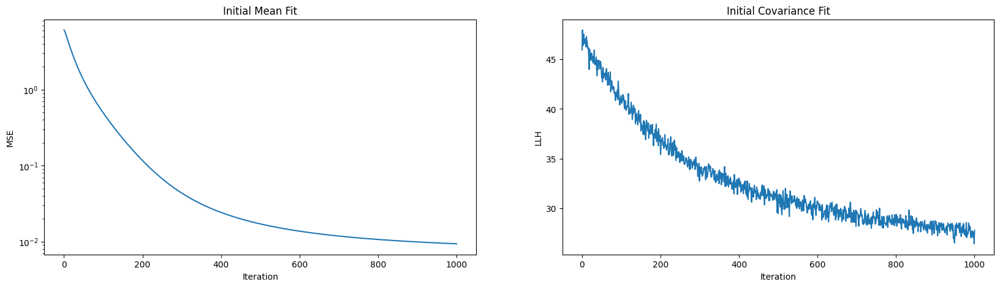

14:45:05 - Full Model Fit


100%|██████████| 10000/10000 [03:16<00:00, 50.98it/s, nll=23.7]


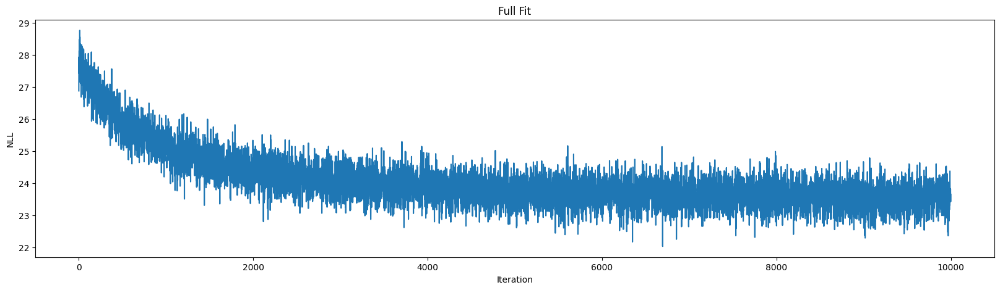

In [6]:
from cytovanni.rainbow import RainbowCalibrator
RBInt = RainbowCalibrator(rb_adatas)
RBInt.fit_fluorescence()

Save the trained model.

In [7]:
RBInt.save(os.path.join(data_path, "rainbow", "RBInt.pt"))

The best way of assessing the quality of the fit is to look at histograms of the rainbow beads. The plot below shows the raw fluorescence on the left, and the fully integrated rainbow beads on the right. The model internally also allows an additional shift, as the background noise may slightly change between measurement days. However, this parameter is not used when calibrating the other data, and the middle column below shows the rainbow beads when only the calibration that is used for the other samples is used. The x-Axis is in units of fluroescence after applying an ArcSinh transformation.

In [8]:
cytovanni.rainbow.plot_eval_calibration(RBInt, rb_adatas, legendkey="rainbow_batch")
plt.savefig(os.path.join(data_path, "rainbow", "RBInt_fit_overview.pdf"))
plt.close()

Note how even at fixed cytometer settings on consecutive days, while some channels are more stable there can be substantial variability in the effective channel gains:

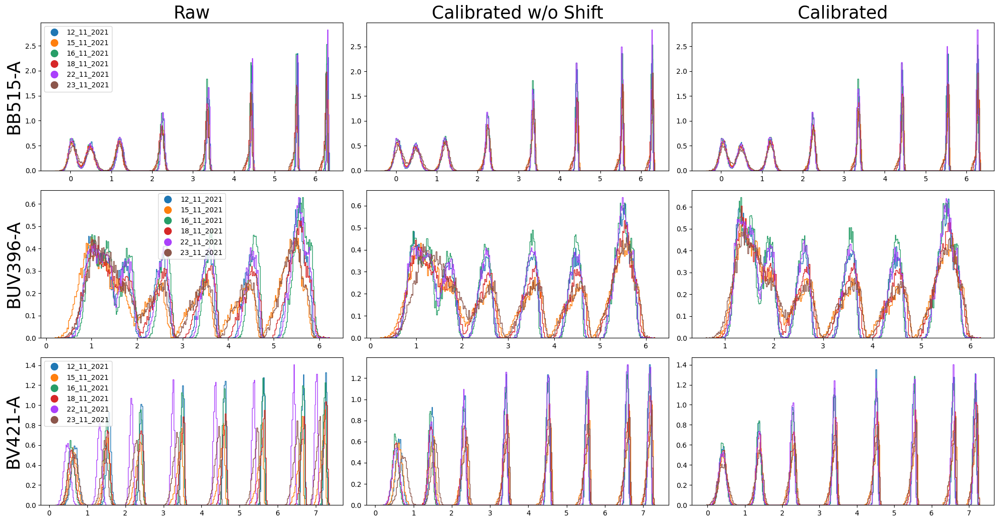

In [9]:
cytovanni.rainbow.plot_eval_calibration(RBInt, rb_adatas, channels=["BB515-A", "BUV396-A", "BV421-A"], legendkey="rainbow_batch")

See the {doc}`tutorial on variable spectra <../integration_variable-spectra/integration_variable-spectra-rainbow>` for an example of how to extend the fitted model to include additional rainbow bead measurements.

### Assessing Cytometer Stability

We can also do the assessment of the stability more formally, splitting the overall change per channel into contributions that are shared across lasers and pure detector effects.

In [10]:
total_logfactors = np.log(RBInt.get_calibration_factors_all())[cytoconfig.channels_fluorescence]

key_laser = cytoconfig.channel_laser_key.loc[total_logfactors.columns]
lasers = key_laser.unique()

extracted = [cytovanni.rainbow.extract_logfactor_laserfactor(total_logfactors.loc[:,key_laser==l]) for l in lasers]
channel_logfactors = pd.concat([e[1] for e in extracted], axis=1)
laser_logfactors = pd.concat([e[0] for e in extracted], axis=1)
laser_logfactors.columns = lasers

total_percentage_change = (np.exp(total_logfactors)-1)*100
channel_percentage_change = (np.exp(channel_logfactors)-1)*100
laser_percentage_change = (np.exp(laser_logfactors)-1)*100

We can see that the overall channels changed by up to $\pm15\%$, especially for the UV channels. However, the individual detectors are much more stable ($\approx\pm5\%$), while the large changes of the UV channels are driven by the variability of the laser, not the detectors.

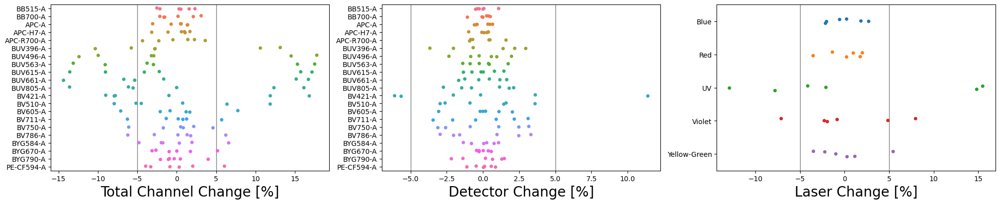

In [11]:
fig, ax = plt.subplots(1,3,figsize=(20,4), layout="constrained")

sns.stripplot(total_percentage_change, orient="y", ax=ax[0])
ax[0].set_xlabel("Total Channel Change [%]", size=20)
sns.stripplot(channel_percentage_change, orient="y", ax=ax[1])
ax[1].set_xlabel("Detector Change [%]", size=20)
sns.stripplot(laser_percentage_change, orient="y", ax=ax[2])
ax[2].set_xlabel("Laser Change [%]", size=20)

for ax_ in ax:
    ax_.axvline(-5, linewidth=1, color="gray")
    ax_.axvline(5, linewidth=1, color="gray")

Note that e.g. the UV laser variability seems to be truly random, with no apparent pattern over time.

Text(0, 0.5, 'UV Laser Change [%]')

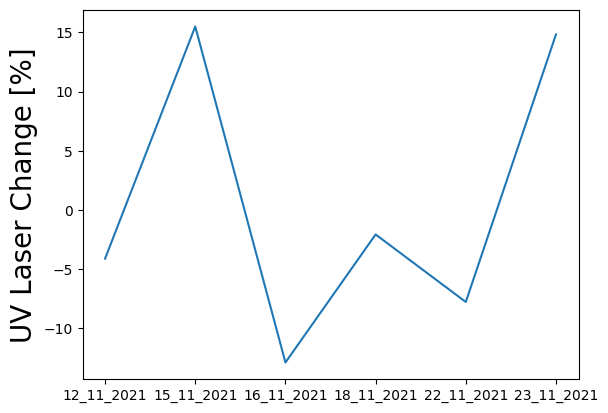

In [12]:
sns.lineplot(laser_percentage_change["UV"])
plt.ylabel("UV Laser Change [%]", size=20)

## Reference Samples

We first load the trained rainbow model.

In [13]:
RBInt = cytovanni.rainbow.RainbowCalibrator.from_saved(os.path.join(data_path, "rainbow", "RBInt.pt"))

As this is no longer sensible after the calibration, we will already apply some gates that filter out events in the non-linear range of the detectors here.

In [14]:
# we apply two generic gates that filter out all events in the non-linear range of the detectors to all samples
gate_minmax_scatter = cytovanni.gating.MinMaxGate(["FSC-A", "FSC-H", "SSC-A", "SSC-H"], 0, 4e5, layer="raw")
# the gate below applies a lower limit of -1e3 and an upper limit of 1.5 * cytoconfig.max_linear_range to cytoconfig.channels_fluorescence
gate_minmax_fluorescence = cytovanni.gating.FluorescenceMinMaxGate(cytoconfig, -1e3, 1.5, layer="raw")
gates_minmax = [gate_minmax_scatter, gate_minmax_fluorescence]

### Applying the Rainbow Calibration to Samples

We can now look at the reference samples. There are two ways of applying the rainbow bead calibration. Either we load the data and apply the model afterwards:

In [15]:
filename = "RF_12_11_2021.fcs"
adata = cytovanni.io.readfcs_sample(os.path.join(raw_data_path, filename), cytoconfig)
adata

AnnData object with n_obs × n_vars = 50000 × 27
    obs: 'Time'
    var: 'pnn', 'pns', 'png', 'pnv', 'pnr'
    uns: 'date', 'UTC', 'cytometer', 'uid', 'cytoconfig', 'set_hash', 'Nevents'
    layers: 'raw'

adata.layers["raw"] contains the raw intensities:

In [16]:
adata.to_df(layer="raw").head()

,FSC-A,FSC-H,FSC-W,SSC-A,SSC-H,SSC-W,BB515-A,BB700-A,APC-A,APC-H7-A,...,BV421-A,BV510-A,BV605-A,BV711-A,BV750-A,BV786-A,BYG584-A,BYG670-A,BYG790-A,PE-CF594-A
0,19526.367188,17015.775391,101062.031250,12285.366211,11489.291016,63747.902344,181.092590,849.561584,176.397476,5536.532227,...,1574.667358,2315.011475,41296.632812,6525.056152,1910.873047,2819.431396,6511.635742,5281.438965,1368.555542,7840.615234
1,29539.156250,26572.064453,108409.492188,19493.628906,18462.031250,67647.468750,61228.421875,9769.267578,7097.398926,38391.957031,...,1408.349243,14822.554688,41205.250000,8749.713867,3234.724609,6356.953125,6358.676270,18552.103516,3867.157227,7633.915527
2,34080.527344,29655.419922,108180.656250,17444.005859,16706.916016,66098.343750,81446.664062,11851.253906,14785.804688,34227.582031,...,1636.520752,17294.457031,38473.859375,8412.615234,4158.621094,8034.634766,6751.511719,25586.539062,3833.980957,6964.921387
3,66891.382812,60518.890625,120547.296875,23121.244141,21712.361328,70012.335938,157193.687500,22910.207031,13432.755859,37603.433594,...,2448.757324,23042.697266,86426.656250,15765.859375,5717.392578,7492.958008,10795.919922,49519.355469,6337.739258,13836.339844
4,26029.572266,17676.789062,116619.414062,61186.476562,48024.093750,90694.093750,718.079651,457.537659,355.933319,1761.150879,...,1517.889404,18351.640625,7655.092773,1076.605469,670.515015,1196.854248,2114.650635,1248.710571,524.601929,1687.334351


After adding the integration, adata.layers["calibrated"] contains the standardized intensities. Note that most channels slightly change, while for example FSC-W doesn't as we do not attempt to calibrate the pulse width.

In [17]:
RBInt.add_calibrated(adata, rainbow_batch='12_11_2021')
adata.to_df(layer="calibrated").head()

,FSC-A,FSC-H,FSC-W,SSC-A,SSC-H,SSC-W,BB515-A,BB700-A,APC-A,APC-H7-A,...,BV421-A,BV510-A,BV605-A,BV711-A,BV750-A,BV786-A,BYG584-A,BYG670-A,BYG790-A,PE-CF594-A
0,19163.573888,16699.628038,101062.031250,11939.073751,11165.437841,63747.902344,177.245386,831.456134,175.162678,5475.751277,...,1432.956066,2131.428475,38364.523480,6117.326095,1794.630089,2644.740318,6397.212984,5231.273968,1364.287110,7773.261212
1,28990.328716,26078.364481,108409.492188,18944.154305,17941.634698,67647.468750,59927.660379,9561.069622,7047.716504,37970.483896,...,1281.605655,13647.109517,38279.628955,8202.972007,3037.948609,5963.078319,6246.941322,18375.888999,3855.095825,7568.337138
2,33447.322670,29104.432248,108180.656250,16952.304791,16235.991589,66098.343750,79716.378007,11598.685653,14682.302743,33851.826081,...,1489.242999,15922.987239,35742.170265,7886.937598,3905.642270,7536.811335,6632.873849,25343.508960,3822.023030,6905.089925
3,65648.563539,59394.470102,120547.296875,22469.516519,21100.346442,70012.335938,153854.200872,22421.955661,13338.725377,37190.616997,...,2228.382803,21215.385591,80290.262359,14780.700842,5369.589973,7028.696698,10606.213528,49049.002914,6317.972278,13717.480147
4,25545.951615,17348.360299,116619.414062,59461.789231,46670.419691,90694.093750,702.824475,447.786835,353.441754,1741.816679,...,1381.287812,16896.334991,7111.572214,1009.331809,629.725990,1122.697537,2077.491898,1236.849872,522.965731,1672.839473


While we added the appropriate rainbow batch manually above, usually the model is also able to infer this automatically from the metadata of the .fcs files:

In [18]:
RBInt.add_calibrated(adata)
adata.to_df(layer="calibrated").head()

,FSC-A,FSC-H,FSC-W,SSC-A,SSC-H,SSC-W,BB515-A,BB700-A,APC-A,APC-H7-A,...,BV421-A,BV510-A,BV605-A,BV711-A,BV750-A,BV786-A,BYG584-A,BYG670-A,BYG790-A,PE-CF594-A
0,19163.573888,16699.628038,101062.031250,11939.073751,11165.437841,63747.902344,177.245386,831.456134,175.162678,5475.751277,...,1432.956066,2131.428475,38364.523480,6117.326095,1794.630089,2644.740318,6397.212984,5231.273968,1364.287110,7773.261212
1,28990.328716,26078.364481,108409.492188,18944.154305,17941.634698,67647.468750,59927.660379,9561.069622,7047.716504,37970.483896,...,1281.605655,13647.109517,38279.628955,8202.972007,3037.948609,5963.078319,6246.941322,18375.888999,3855.095825,7568.337138
2,33447.322670,29104.432248,108180.656250,16952.304791,16235.991589,66098.343750,79716.378007,11598.685653,14682.302743,33851.826081,...,1489.242999,15922.987239,35742.170265,7886.937598,3905.642270,7536.811335,6632.873849,25343.508960,3822.023030,6905.089925
3,65648.563539,59394.470102,120547.296875,22469.516519,21100.346442,70012.335938,153854.200872,22421.955661,13338.725377,37190.616997,...,2228.382803,21215.385591,80290.262359,14780.700842,5369.589973,7028.696698,10606.213528,49049.002914,6317.972278,13717.480147
4,25545.951615,17348.360299,116619.414062,59461.789231,46670.419691,90694.093750,702.824475,447.786835,353.441754,1741.816679,...,1381.287812,16896.334991,7111.572214,1009.331809,629.725990,1122.697537,2077.491898,1236.849872,522.965731,1672.839473


To be interoperable with other software, we will here apply the calibrated to the .fcs files directly and save the modified values.

Note that we now already exclude events with fluorescence/scatter values in the non-linear range.

In [19]:
from pathlib import Path
Path(os.path.join(data_path, "ref", "data_rainbow_calibrated")).mkdir(parents=True, exist_ok=True)

for file in list(filter(lambda x: x.endswith(".fcs") and x.startswith("RF"), os.listdir(raw_data_path))):
    filepath = os.path.join(raw_data_path, file)
    filepath_new = os.path.join(data_path, "ref", "data_rainbow_calibrated", file)
    RBInt.make_calibrated_fcs(filepath, filepath_new, cytoconfig, gates=gates_minmax)

The new files then contain the standardized fluorescence values:

In [20]:
cytovanni.io.readfcs_sample(os.path.join(data_path, "ref", "data_rainbow_calibrated", filename), cytoconfig).to_df(layer="raw").head()

,FSC-A,FSC-H,FSC-W,SSC-A,SSC-H,SSC-W,BB515-A,BB700-A,APC-A,APC-H7-A,...,BV421-A,BV510-A,BV605-A,BV711-A,BV750-A,BV786-A,BYG584-A,BYG670-A,BYG790-A,PE-CF594-A
0,19163.574219,16699.628906,101062.031250,11939.074219,11165.437500,63747.902344,177.245392,831.456116,175.162674,5475.751465,...,1432.956055,2131.428467,38364.523438,6117.326172,1794.630127,2644.740234,6397.212891,5231.273926,1364.287109,7773.261230
1,28990.328125,26078.365234,108409.492188,18944.154297,17941.634766,67647.468750,59927.660156,9561.069336,7047.716309,37970.484375,...,1281.605713,13647.109375,38279.628906,8202.971680,3037.948730,5963.078125,6246.941406,18375.888672,3855.095703,7568.336914
2,33447.324219,29104.431641,108180.656250,16952.304688,16235.991211,66098.343750,79716.375000,11598.685547,14682.302734,33851.824219,...,1489.243042,15922.987305,35742.171875,7886.937500,3905.642334,7536.811523,6632.874023,25343.509766,3822.022949,6905.089844
3,65648.562500,59394.468750,120547.296875,22469.515625,21100.345703,70012.335938,153854.203125,22421.955078,13338.725586,37190.617188,...,2228.382812,21215.384766,80290.265625,14780.701172,5369.589844,7028.696777,10606.213867,49049.003906,6317.972168,13717.480469
4,25545.951172,17348.359375,116619.414062,59461.789062,46670.417969,90694.093750,702.824463,447.786835,353.441742,1741.816650,...,1381.287842,16896.335938,7111.572266,1009.331787,629.726013,1122.697510,2077.491943,1236.849854,522.965759,1672.839478


### Applying the Rainbow Calibration to Spectra

In our case, the spectra were recorded with batch '12_11_2021', so we adjust it from this batch into the calibrated intensity reference frame.

In [27]:
panel_spectra = pd.read_table(os.path.join(raw_data_path, "panel_spectra.csv"), sep=",", index_col=0)
panel_spectra_calibrated = RBInt.get_calibrated_spectra(panel_spectra.T, "12_11_2021", spectral=False).T # transpose on both sides, as this function expects shape (channel, dye)
panel_spectra_calibrated.to_csv(os.path.join(data_path, "ref", "panel_spectra_calibrated.csv"))

### Rainbow Calibration Effect

In this dataset the unmixing is generally not drastically affected by the cytometer variability, but we nevertheless see some changes.

First, we load all the reference samples after rainbow calibration. Here, the samples are clean enough that we do not need any additional gating to make our point.

In [26]:
folder = os.path.join(data_path, "ref", "data_rainbow_calibrated")
files = sorted(list(filter(lambda x: x.endswith(".fcs"), os.listdir(folder))))
adatas = []
for file in files:
    adata = cytovanni.io.readfcs_sample(os.path.join(folder, file), cytoconfig) # without gates here, as this was already done
    adata.uns["date"] = file.replace(".fcs","")
    adata.obs["date"] = file.replace(".fcs","")
    adatas.append(adata)

For comparison, we also load the data as it was recorded.

In [24]:
adatas_original = []
for file in files:
    adata = cytovanni.io.readfcs_sample(os.path.join(raw_data_path, file), cytoconfig, gates=gates_minmax)
    adata.uns["date"] = file.replace(".fcs","")
    adata.obs["date"] = file.replace(".fcs","")
    adatas_original.append(adata)

We then use the single stain spectra to do the unmixing for both of them.

In [28]:
panel_spectra = pd.read_table(os.path.join(raw_data_path, "panel_spectra.csv"), sep=",", index_col=0)
panel_spectra_calibrated = pd.read_table(os.path.join(data_path, "ref", "panel_spectra_calibrated.csv"), sep=",", index_col=0)

for ad in adatas:
    ad.obsm["unmx"] = cytovanni.utils.apply_unmixing_lstsq(panel_spectra_calibrated, ad.to_df(layer="raw"))
    ad.obsm["unmx_ash"] = cytovanni.utils.apply_arcsinh(ad.obsm["unmx"], 1500)
for ad in adatas_original:
    ad.obsm["unmx"] = cytovanni.utils.apply_unmixing_lstsq(panel_spectra, ad.to_df(layer="raw"))
    ad.obsm["unmx_ash"] = cytovanni.utils.apply_arcsinh(ad.obsm["unmx"], 1500)

adata = cytovanni.utils.anndata_concat(adatas, make_unique=True, permute=True)
adata_original = cytovanni.utils.anndata_concat(adatas_original, make_unique=True, permute=True)

In this example, the spillover of BB515 into BV510 is especially affected by the cytometer instability, leading to a clear batch effect unless this is corrected.

Text(0.5, 1.0, 'Rainbow Standardization')

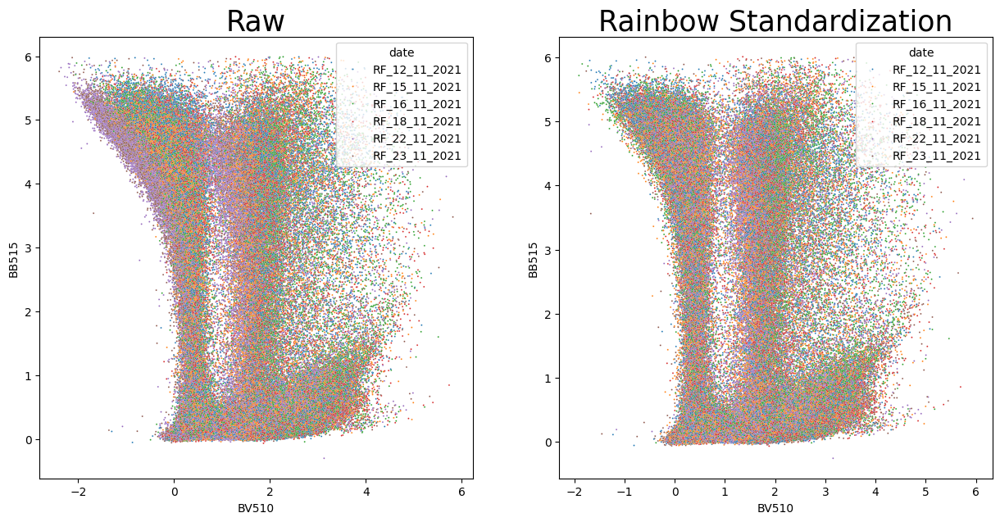

In [29]:
xkey, ykey = "BV510", "BB515"

fig, ax = plt.subplots(1,2,figsize=(15,7))
sns.scatterplot(x=adata_original.obsm["unmx_ash"][xkey],
                y=adata_original.obsm["unmx_ash"][ykey],
                hue=adata_original.obs["date"],
                hue_order=sorted(adata_original.obs["date"].unique()),
                s=2, ax=ax[0], rasterized=True)
sns.scatterplot(x=adata.obsm["unmx_ash"][xkey],
                y=adata.obsm["unmx_ash"][ykey],
                hue=adata.obs["date"],
                hue_order=sorted(adata.obs["date"].unique()),
                s=2, ax=ax[1], rasterized=True)
ax[0].set_title("Raw", size=25)
ax[1].set_title("Rainbow Standardization", size=25)

### Remaining Batch Effect

Even after the cytometer has been standardized, we still see some batch effects in the marker abundances. This problem will be adressed in the next tutorial.

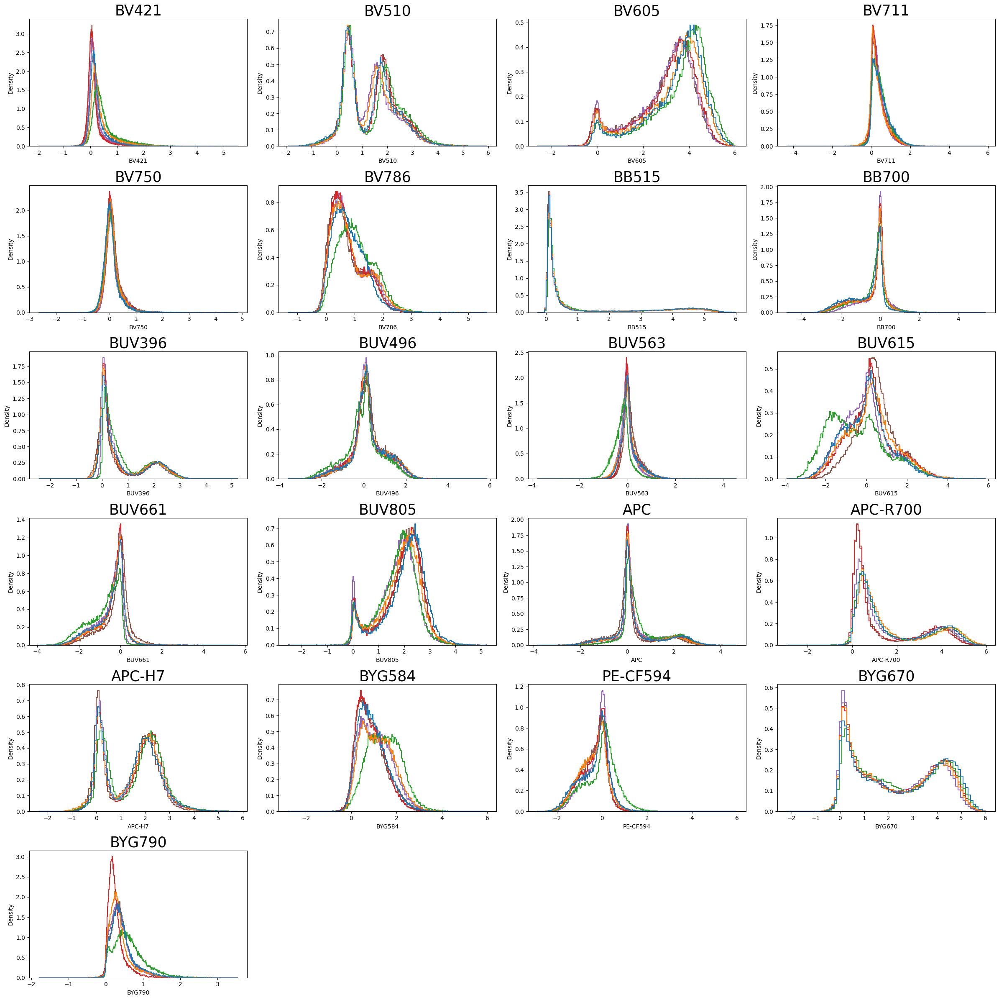

In [30]:
markers = adata.obsm["unmx_ash"].columns
fig, ax = cytovanni.utils.unrolled_subplots(len(markers))
for i, key in enumerate(markers):
    sns.histplot(x=adata.obsm["unmx_ash"][key], hue=adata.obs["date"],
                    hue_order=sorted(adata.obs["date"].unique()), ax=ax[i], fill=False, element="step", legend=False, stat="density", common_norm=False)
    ax[i].set_title(key, size=25)
fig.tight_layout()